# 04 — Árvore de Decisão

In [1]:
from pathlib import Path
import sys
import warnings

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import plot_tree

from src.config import *
from src.prepare_data import preparar_classificacao, preparar_regressao
from src.metrics import calcular_metricas_classificacao, calcular_metricas_regressao
from src.models import (
    GRADE_ARVORE_CLASSIFICACAO,
    GRADE_ARVORE_REGRESSAO,
    buscar_hiperparametros,
    criar_arvore_classificacao,
    criar_arvore_regressao,
    importancias_features,
    nomes_features,
    salvar_modelo,
)
from src.interpretability import extrair_regras_arvore
from src.visualization import plotar_residuos, plotar_importancia_features

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
criar_diretorios()

X_train_c, X_test_c, y_train_c, y_test_c = preparar_classificacao()
X_train_r, X_test_r, y_train_r, y_test_r = preparar_regressao()

print("Classificação:", X_train_c.shape, X_test_c.shape)
print("Regressão:    ", X_train_r.shape, X_test_r.shape)

Classificação: (40000, 9) (10000, 9)
Regressão:     (40000, 8) (10000, 8)


## 1. Árvores de referência (sem ajuste)

In [2]:
def metricas_classificacao_modelo(modelo, nome: str) -> dict:
    pred_treino = modelo.predict(X_train_c)
    pred_teste = modelo.predict(X_test_c)
    m_treino = calcular_metricas_classificacao(
        y_train_c, pred_treino, classes=CLASSES, classe_positiva=CLASSE_POSITIVA
    )
    m_teste = calcular_metricas_classificacao(
        y_test_c, pred_teste, classes=CLASSES, classe_positiva=CLASSE_POSITIVA
    )
    return {
        "Modelo": nome,
        "F1 Macro Treino": m_treino["F1-Score (Macro)"],
        "F1 Macro Teste": m_teste["F1-Score (Macro)"],
        "F1 High Teste": m_teste["F1-Score (High)"],
        "Accuracy Teste": m_teste["Accuracy"],
    }


def metricas_regressao_modelo(modelo, nome: str) -> dict:
    pred_treino = modelo.predict(X_train_r)
    pred_teste = modelo.predict(X_test_r)
    m_treino = calcular_metricas_regressao(y_train_r, pred_treino)
    m_teste = calcular_metricas_regressao(y_test_r, pred_teste)
    return {
        "Modelo": nome,
        "MAE Treino": m_treino["MAE"],
        "MAE Teste": m_teste["MAE"],
        "RMSE Teste": m_teste["RMSE"],
        "R2 Teste": m_teste["R2"],
    }


arvores_classificacao = {
    "Árvore Gini": criar_arvore_classificacao("gini"),
    "Árvore Entropia": criar_arvore_classificacao("entropy"),
}
arvores_regressao = {
    "Árvore MSE": criar_arvore_regressao("squared_error"),
    "Árvore MAE": criar_arvore_regressao("absolute_error"),
}

linhas_c = []
for nome, modelo in arvores_classificacao.items():
    modelo.fit(X_train_c, y_train_c)
    linhas_c.append(metricas_classificacao_modelo(modelo, nome))

linhas_r = []
for nome, modelo in arvores_regressao.items():
    modelo.fit(X_train_r, y_train_r)
    linhas_r.append(metricas_regressao_modelo(modelo, nome))

display(pd.DataFrame(linhas_c).round(4))
display(pd.DataFrame(linhas_r).round(4))

,Modelo,F1 Macro Treino,F1 Macro Teste,F1 High Teste,Accuracy Teste
0,Árvore Gini,1.0,0.5843,0.8787,0.8103
1,Árvore Entropia,1.0,0.6216,0.8844,0.8186


,Modelo,MAE Treino,MAE Teste,RMSE Teste,R2 Teste
0,Árvore MSE,0.0,8.6818,10.9302,0.5054
1,Árvore MAE,0.0,8.6459,10.8945,0.5086


Sem poda, as árvores crescem até separar quase perfeitamente o treino. O
resultado é o padrão clássico de **overfitting**: erro de treino muito baixo e
erro de teste bem maior. A busca abaixo controla a complexidade.

## 2. Ajuste de hiperparâmetros — classificação

In [3]:
busca_c = buscar_hiperparametros(
    criar_arvore_classificacao(),
    GRADE_ARVORE_CLASSIFICACAO,
    X_train_c,
    y_train_c,
    problema="classificacao",
    scoring="f1_macro",
)

print("Melhores hiperparâmetros:", busca_c.best_params_)
print(f"F1 macro médio na validação cruzada: {busca_c.best_score_:.4f}")
print(f"Combinações avaliadas: {len(busca_c.cv_results_['params'])}")

Melhores hiperparâmetros: {'model__ccp_alpha': 0.0, 'model__criterion': 'entropy', 'model__max_depth': 10, 'model__min_samples_leaf': 10}
F1 macro médio na validação cruzada: 0.6781
Combinações avaliadas: 60


In [4]:
arvore_c = busca_c.best_estimator_
arvore_c.fit(X_train_c, y_train_c)

linha_c = metricas_classificacao_modelo(arvore_c, "Árvore ajustada")
display(pd.DataFrame([linha_c]).round(4))

def descrever_complexidade(modelo, nome: str) -> dict:
    arvore = modelo.named_steps["model"]
    return {
        "Modelo": nome,
        "Profundidade": arvore.get_depth(),
        "Nós": arvore.tree_.node_count,
        "Folhas": arvore.get_n_leaves(),
    }

display(pd.DataFrame([
    descrever_complexidade(arvore_c, "Árvore ajustada"),
    descrever_complexidade(arvores_classificacao["Árvore Gini"], "Árvore Gini sem poda"),
]).round(4))

salvar_modelo(arvore_c, "arvore_classificacao")

,Modelo,F1 Macro Treino,F1 Macro Teste,F1 High Teste,Accuracy Teste
0,Árvore ajustada,0.7473,0.6649,0.9119,0.8595


,Modelo,Profundidade,Nós,Folhas
0,Árvore ajustada,10,1469,735
1,Árvore Gini sem poda,25,10355,5178


WindowsPath('C:/Users/lucas/OneDrive/Documentos/avaliacao-comparativa-modelos-ia/artifacts/models/arvore_classificacao.joblib')

A árvore ajustada usa `ccp_alpha` para podar ramos que não melhoram a impureza
de forma significativa. O critério escolhido (Gini ou entropia) e a
profundidade são definidos pela validação cruzada, não pelo teste.

## 3. Visualização e regras extraídas

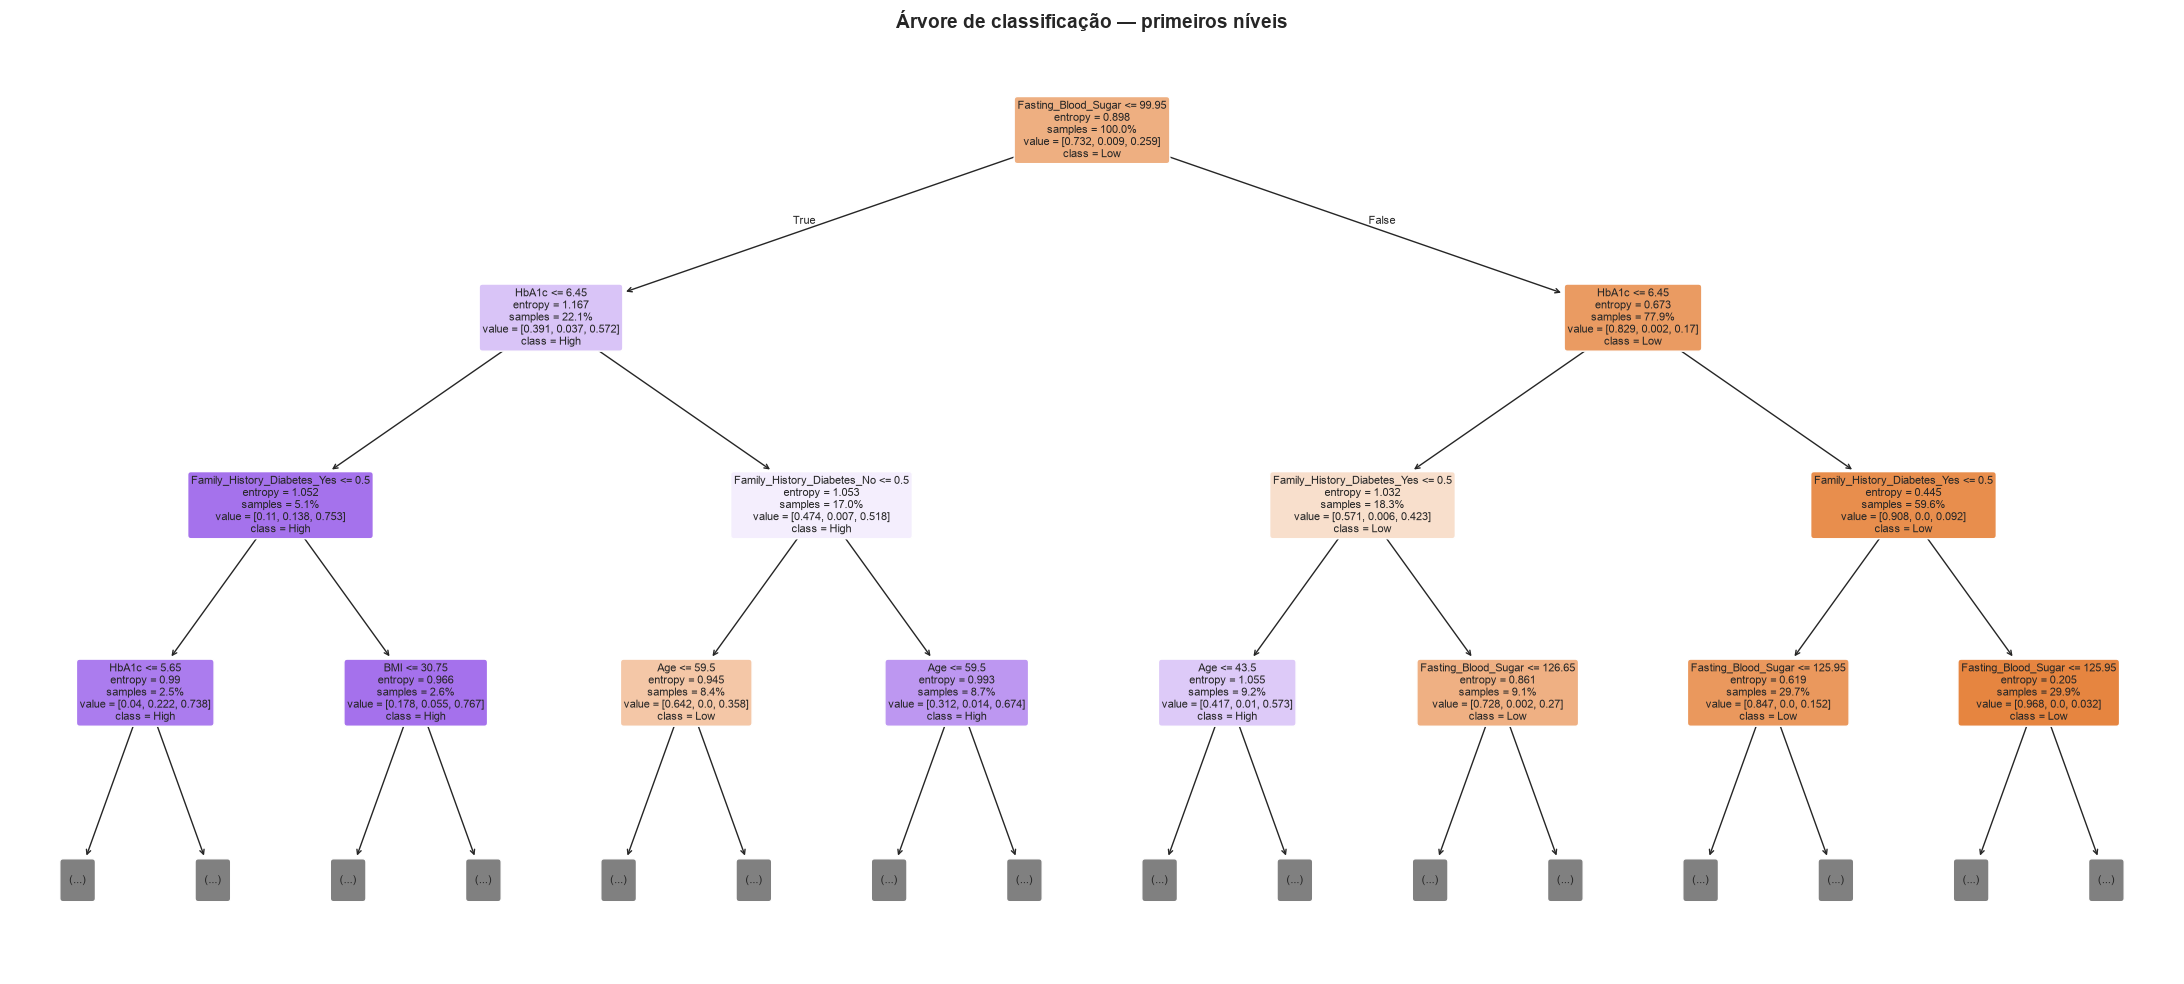

In [5]:
plt.figure(figsize=(22, 10))
plot_tree(
    arvore_c.named_steps["model"],
    feature_names=nomes_features(arvore_c),
    class_names=CLASSES,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8,
    proportion=True,
)
plt.title("Árvore de classificação — primeiros níveis", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "arvore_decisao_primeiros_niveis.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
regras_arvore = extrair_regras_arvore(arvore_c, n_regras=3)
display(regras_arvore[["Regra", "Classe", "Probabilidade", "Amostras", "Condições"]])
regras_arvore.to_csv(
    TABLES_DIR / "regras_arvore_classificacao.csv", index=False, encoding="utf-8"
)

,Regra,Classe,Probabilidade,Amostras,Condições
0,ARV1,High,1.000000,1958,Fasting_Blood_Sugar > 125.95 E HbA1c > 6.45 E ...
1,ARV2,Low,0.621622,37,Fasting_Blood_Sugar <= 99.95 E HbA1c <= 5.65 E...
2,ARV3,Moderate,0.742857,175,Fasting_Blood_Sugar > 125.95 E HbA1c > 6.45 E ...


As três regras acima são folhas reais da árvore; as condições vêm dos cortes
dos nós e a probabilidade é a proporção da classe na folha. Observe que a
árvore pode combinar atributos numéricos e categóricos no mesmo caminho, algo
que o sistema especialista também faz, mas com limites definidos por
especialista em vez de otimizados por impureza.

A comparação detalhada com as regras do especialista é feita abaixo, depois do
ajuste da árvore de regressão.

## 4. Ajuste de hiperparâmetros — regressão

In [7]:
busca_r = buscar_hiperparametros(
    criar_arvore_regressao(),
    GRADE_ARVORE_REGRESSAO,
    X_train_r,
    y_train_r,
    problema="regressao",
    scoring="neg_root_mean_squared_error",
)

print("Melhores hiperparâmetros:", busca_r.best_params_)
print(f"RMSE médio na validação cruzada: {-busca_r.best_score_:.4f}")
print(f"Combinações avaliadas: {len(busca_r.cv_results_['params'])}")

Melhores hiperparâmetros: {'model__ccp_alpha': 0.0005, 'model__criterion': 'squared_error', 'model__max_depth': 10, 'model__min_samples_leaf': 20}
RMSE médio na validação cruzada: 7.9661
Combinações avaliadas: 60


In [8]:
arvore_r = busca_r.best_estimator_
arvore_r.fit(X_train_r, y_train_r)

pred_treino_r = arvore_r.predict(X_train_r)
pred_teste_r = arvore_r.predict(X_test_r)

metricas_arvore_r = pd.DataFrame(
    {
        "Treino": calcular_metricas_regressao(y_train_r, pred_treino_r),
        "Teste": calcular_metricas_regressao(y_test_r, pred_teste_r),
    }
)
display(metricas_arvore_r.round(4))

display(pd.DataFrame([
    descrever_complexidade(arvore_r, "Árvore ajustada"),
    descrever_complexidade(arvores_regressao["Árvore MSE"], "Árvore MSE sem poda"),
]).round(4))

salvar_modelo(arvore_r, "arvore_regressao")

,Treino,Teste
MAE,5.8279,6.2824
MSE,53.3066,62.0958
RMSE,7.3011,7.8801
MAPE (%),8.5424,9.2179
R2,0.7813,0.7429
MedAE,4.9839,5.2752


,Modelo,Profundidade,Nós,Folhas
0,Árvore ajustada,10,1583,792
1,Árvore MSE sem poda,35,69915,34958


WindowsPath('C:/Users/lucas/OneDrive/Documentos/avaliacao-comparativa-modelos-ia/artifacts/models/arvore_regressao.joblib')

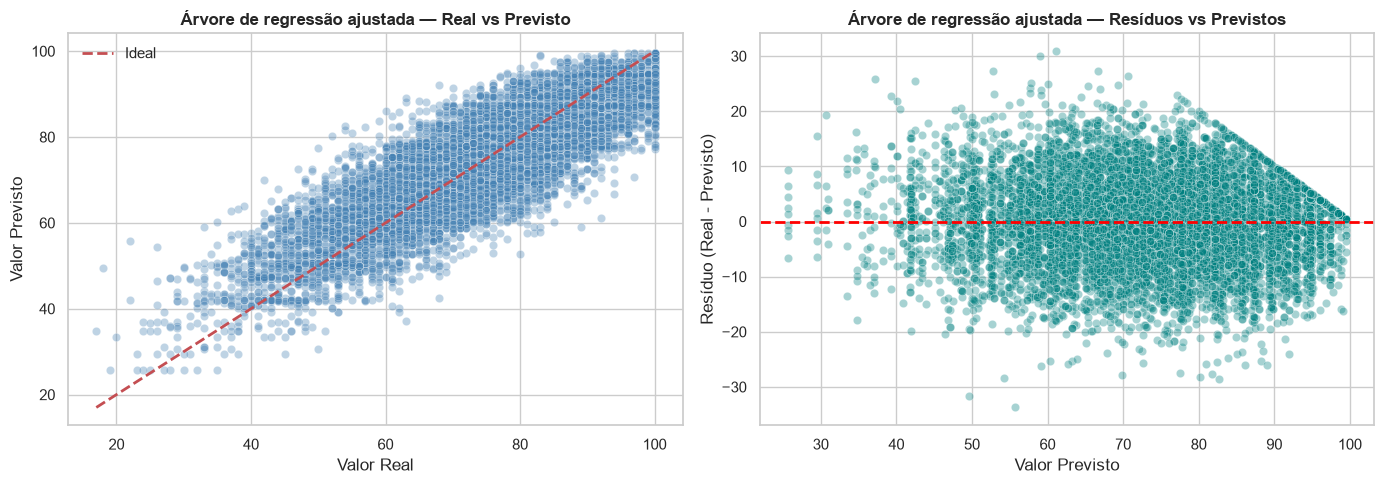

In [9]:
plotar_residuos(
    y_test_r,
    pred_teste_r,
    titulo="Árvore de regressão ajustada",
    arquivo_saida=FIGURES_DIR / "residuos_arvore.png",
)
plt.show()

A árvore de regressão tem resíduos em **degraus**: cada folha prevê uma
constante (a média dos exemplos de treino naquela região). Por isso ela não
reproduz bem a suavidade do escore contínuo, embora capture as interações entre
as variáveis.

## 5. Importância das variáveis na árvore

,Importância
Fasting_Blood_Sugar,0.2905
HbA1c,0.2181
Age,0.1285
BMI,0.1043
Family_History_Diabetes,0.0956
Hypertension,0.0477
Diet_Quality,0.0419
PCOS,0.0370
Heart_Disease,0.0365


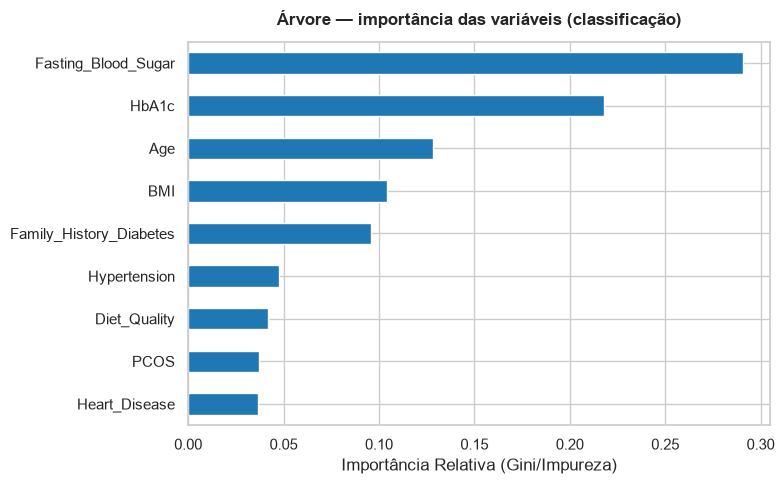

In [10]:
importancia_arvore = importancias_features(arvore_c)
display(importancia_arvore.round(4).to_frame("Importância"))
plotar_importancia_features(
    importancia_arvore,
    titulo="Árvore — importância das variáveis (classificação)",
    arquivo_saida=FIGURES_DIR / "importancia_features_arvore.png",
)
plt.show()

## 6. Comparação das três regras da árvore com o sistema especialista

| Regra extraída da árvore | Regra do especialista equivalente | Leitura |
|---|---|---|
| **ARV1** — glicemia > 125,95 **E** HbA1c > 6,45 **E** histórico familiar **E** idade > 59,5 **E** hipertensão → **High** (1.958 amostras, pureza 100%) | **R1** — glicemia ≥ 126 **E** HbA1c ≥ 6,5 → **High** | A árvore recuperou os mesmos limiares clínicos (125,95 ≈ 126 e 6,45 ≈ 6,5) e acrescentou histórico, idade e hipertensão. O especialista é mais abrangente; a árvore é mais restrita e pura. |
| **ARV2** — glicemia ≤ 99,95 **E** HbA1c ≤ 5,65 **E** sem histórico **E** idade ≤ 63,5 **E** IMC > 30,55 **E** dieta não ruim **E** sem PCOS **E** sem hipertensão → **Low** (37 amostras, 62,2%) | **R3** — glicemia < 100 **E** HbA1c < 5,7 → **Low** | Mesmos limiares de glicemia/HbA1c, mas a árvore exige um perfil específico (obesidade, sem comorbidades). A regra do especialista é muito mais simples e cobre mais casos. |
| **ARV3** — glicemia > 125,95 **E** HbA1c > 6,45 **E** sem histórico **E** idade ≤ 44,5 **E** IMC ≤ 29,95 **E** sem doença cardíaca/PCOS/hipertensão **E** dieta não ruim → **Moderate** (175 amostras, 74,3%) | **R1** / **R2** — dependendo da faixa | É o caso mais interessante: a árvore encontra um subgrupo **jovem, magro e sem comorbidades** com glicemia e HbA1c altas que ela classifica como *Moderate*, enquanto o especialista (R1) classificaria como *High*. A árvore aprendeu que o contexto modifica o risco; o especialista usa apenas os critérios diagnósticos. |

As regras da árvore são **mais específicas e menos compactas** que as do
especialista: cada folha descreve um caminho completo, com limiares quebrados
(por exemplo, 99,95) aprendidos dos dados. O especialista usa poucos limiares
clínicos e cobre uma região maior, mas deixa casos sem classificação. A árvore
também revela interações (idade, IMC, comorbidades) que o especialista não
modela explicitamente.

## 7. Tabelas consolidadas

In [11]:
tabela_classificacao = pd.concat(
    [
        pd.DataFrame(linhas_c),
        pd.DataFrame([linha_c]),
        pd.DataFrame([{
            "Modelo": "Árvore Gini sem poda",
            **{k: v for k, v in metricas_classificacao_modelo(
                arvores_classificacao["Árvore Gini"], "x"
            ).items() if k != "Modelo"},
        }]),
    ],
    ignore_index=True,
)
display(tabela_classificacao.round(4))

tabela_regressao = pd.concat(
    [
        pd.DataFrame(linhas_r),
        pd.DataFrame([{
            "Modelo": "Árvore ajustada",
            "MAE Treino": metricas_arvore_r.loc["MAE", "Treino"],
            "MAE Teste": metricas_arvore_r.loc["MAE", "Teste"],
            "RMSE Teste": metricas_arvore_r.loc["RMSE", "Teste"],
            "R2 Teste": metricas_arvore_r.loc["R2", "Teste"],
        }]),
        pd.DataFrame([{
            "Modelo": "Árvore MSE sem poda",
            **{k: v for k, v in metricas_regressao_modelo(
                arvores_regressao["Árvore MSE"], "x"
            ).items() if k != "Modelo"},
        }]),
    ],
    ignore_index=True,
)
display(tabela_regressao.round(4))

tabela_classificacao.to_csv(
    TABLES_DIR / "desempenho_arvore_classificacao.csv", index=False, encoding="utf-8"
)
tabela_regressao.to_csv(
    TABLES_DIR / "desempenho_arvore_regressao.csv", index=False, encoding="utf-8"
)

complexidades = pd.DataFrame([
    descrever_complexidade(arvores_classificacao["Árvore Gini"], "Classificação — Gini sem poda"),
    descrever_complexidade(arvore_c, "Classificação — ajustada"),
    descrever_complexidade(arvores_regressao["Árvore MSE"], "Regressão — MSE sem poda"),
    descrever_complexidade(arvore_r, "Regressão — ajustada"),
])
display(complexidades)
complexidades.to_csv(
    TABLES_DIR / "complexidade_arvore.csv", index=False, encoding="utf-8"
)

,Modelo,F1 Macro Treino,F1 Macro Teste,F1 High Teste,Accuracy Teste
0,Árvore Gini,1.0000,0.5843,0.8787,0.8103
1,Árvore Entropia,1.0000,0.6216,0.8844,0.8186
2,Árvore ajustada,0.7473,0.6649,0.9119,0.8595
3,Árvore Gini sem poda,1.0000,0.5843,0.8787,0.8103


,Modelo,MAE Treino,MAE Teste,RMSE Teste,R2 Teste
0,Árvore MSE,0.0000,8.6818,10.9302,0.5054
1,Árvore MAE,0.0000,8.6459,10.8945,0.5086
2,Árvore ajustada,5.8279,6.2824,7.8801,0.7429
3,Árvore MSE sem poda,0.0000,8.6818,10.9302,0.5054


,Modelo,Profundidade,Nós,Folhas
0,Classificação — Gini sem poda,25,10355,5178
1,Classificação — ajustada,10,1469,735
2,Regressão — MSE sem poda,35,69915,34958
3,Regressão — ajustada,10,1583,792
